# Analysing WACCM-X output with xarray

This notebook works through real output from **WACCM-X**, NCAR's whole-atmosphere model, which
extends from the surface to roughly 600 km and includes the ionosphere. The run used here
covers December 2025, driven by observed solar and geomagnetic conditions.

The aim is to cover the operations that most atmospheric analyses are built from:

1. opening one or many netCDF files,
2. zonal averages,
3. maps on a single level,
4. time–height sections,
5. time series at a point,
6. time averages and area-weighted averages.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Keep units and long names through operations such as .mean(), so plots stay labelled
xr.set_options(keep_attrs=True)

## 1. xarray in brief

A numpy array is an unlabelled block of numbers: you have to keep track yourself of which
axis is latitude and which index corresponds to which time. An **xarray `DataArray`** attaches
that information to the array:

* **dimensions**: names for the axes, e.g. `("time", "lev", "lat", "lon")`;
* **coordinates**: the values along each axis, e.g. the actual latitudes;
* **attributes**: metadata such as `units` and `long_name`.

A **`Dataset`** is a collection of DataArrays sharing coordinates, which maps directly onto
a netCDF file.

A small example with made-up temperatures:

In [2]:
temps = xr.DataArray(
    [[5, 7, 6, 8],
     [12, 14, 13, 15],
     [20, 22, 21, 19]],
    dims=["city", "day"],
    coords={"city": ["Leeds", "Madrid", "Cairo"], "day": [1, 2, 3, 4]},
    attrs={"units": "degC", "long_name": "temperature"},
)
temps

<xarray.DataArray (city: 3, day: 4)> Size: 96B
array([[ 5,  7,  6,  8],
       [12, 14, 13, 15],
       [20, 22, 21, 19]])
Coordinates:
  * city     (city) <U6 72B 'Leeds' 'Madrid' 'Cairo'
  * day      (day) int64 32B 1 2 3 4
Attributes:
    units:      degC
    long_name:  temperature

Indexing and reductions use dimension names rather than axis numbers:

* `.sel(...)` selects by coordinate value,
* `.isel(...)` selects by integer position,
* `.mean("day")` reduces along a named dimension.

In [3]:
print(temps.sel(city="Leeds").values)
print(temps.isel(day=0).values)
print(temps.mean("day").values)

[5 7 6 8]
[ 5 12 20]
[ 6.5 13.5 20.5]


### Plotting

Every DataArray has a `.plot()` method that uses the coordinates and attributes to label the
figure. A 1D array gives a line plot:

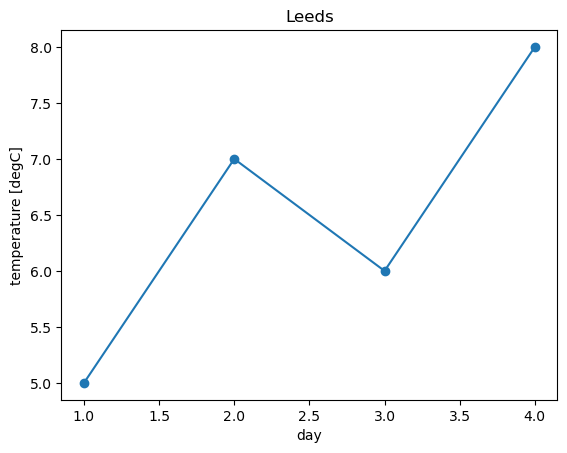

In [4]:
leeds = temps.sel(city="Leeds")

leeds.plot(marker="o")
plt.title("Leeds")
plt.show()

`.plot()` is a thin wrapper around **matplotlib**. The equivalent call with `plt.plot(x, y)`
requires you to pass the coordinate and write the labels yourself:

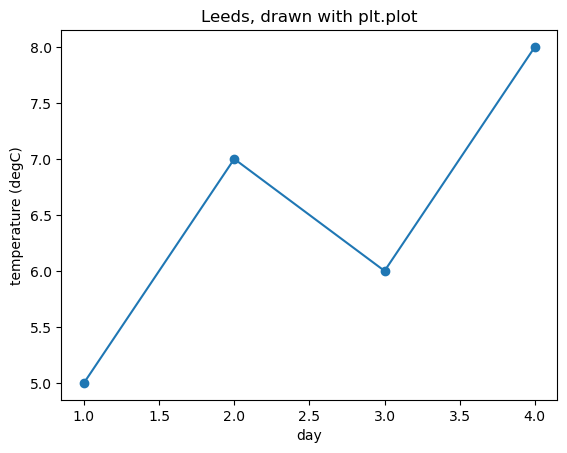

In [5]:
plt.plot(leeds["day"], leeds, marker="o")
plt.xlabel("day")
plt.ylabel("temperature (degC)")
plt.title("Leeds, drawn with plt.plot")
plt.show()

A 2D array gives a colour-mesh plot, with the dimensions assigned to the axes automatically:

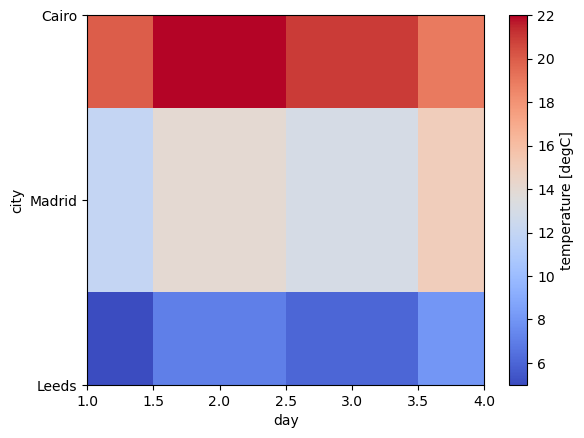

In [6]:
temps.plot(cmap="coolwarm")
plt.show()

## 2. Opening the model output

Two kinds of CAM history file are used:

| tape | contents |
|---|---|
| `h2` | **daily means** on the global 1.9° × 2.5° grid, 145 levels, one time per file |
| `h3` | **station output** every 5-minute model timestep at two locations: 20°E 70°N (Tromsø) and 13°E 55°N (Copenhagen) |

Note on CAM time stamps: an averaged record is labelled with the time at the **end** of its
averaging window. The file `...h2.2025-12-15-00000.nc` therefore holds the mean over
14 December; the window itself is stored in `time_bnds`.

### One file: `open_dataset`

In [7]:
DATA_DIR = "/uolstore/Research/b/b0252/Data/waccmx_campaign_simulations/waccmx_campaign_processed_reduced/reduced/msc"
CASE = "waccmx_campaign.001.30minKp"

one_day = xr.open_dataset(f"{DATA_DIR}/{CASE}.cam.h2.2025-12-15-00000.nc")
one_day

<xarray.Dataset> Size: 297MB
Dimensions:          (lat: 96, lon: 144, mlat: 97, mlon: 80, lev: 145,
                      ilev: 146, time: 1, nbnd: 2)
Coordinates:
  * lat              (lat) float64 768B -90.0 -88.11 -86.21 ... 86.21 88.11 90.0
  * lon              (lon) float64 1kB 0.0 2.5 5.0 7.5 ... 352.5 355.0 357.5
  * mlat             (mlat) float64 776B -90.0 -88.12 -86.24 ... 88.12 90.0
  * mlon             (mlon) float64 640B -180.0 -175.5 -171.0 ... 171.0 175.5
  * lev              (lev) float64 1kB 4.055e-10 5.207e-10 ... 977.5 992.5
  * ilev             (ilev) float64 1kB 3.551e-10 4.559e-10 ... 985.0 1e+03
  * time             (time) datetime64[ns] 8B 2025-12-15
Dimensions without coordinates: nbnd
Data variables: (12/76)
    gw               (lat) float64 768B ...
    hyam             (lev) float64 1kB ...
    hybm             (lev) float64 1kB ...
    P0               float64 8B ...
    hyai             (ilev) float64 1kB ...
    hybi             (ilev) float64 1kB ...
    ...               ...
    WI               (time, lev, lat, lon) float32 8MB ...
    Z3GM             (time, lev, lat, lon) float32 8MB ...
    e                (time, lev, lat, lon) float32 8MB ...
    r_elec1          (time, lev, lat, lon) float32 8MB ...
    r_elec2          (time, lev, lat, lon) float32 8MB ...
    r_elec3          (time, lev, lat, lon) float32 8MB ...
Attributes:
    Conventions:       CF-1.0
    source:            CAM
    case:              waccmx_campaign.001.30minKp
    logname:           mmkupilas
    host:              ln01
    initial_file:      /scratch-nvme/n02/n02/phyfs/cesm_inputdata/atm/waccm/i...
    topography_file:   /scratch-nvme/n02/n02/phyfs/cesm_inputdata/atm/cam/met...
    model_doi_url:     https://doi.org/10.5065/D67H1H0V
    time_period_freq:  day_1

Expand **Dimensions**, **Coordinates** and **Data variables** above to see the contents. The
main dimensions are:

* `lat` (−90 to 90) and `lon` (0 to 357.5, degrees east),
* `lev`: hybrid model levels, labelled by approximate pressure in hPa, ordered from the model
  top (~4 × 10⁻¹⁰ hPa) down to the surface,
* `time`.

`open_dataset` is **lazy**: it reads the metadata immediately but only reads values from disk
when they are needed.

### Many files: `open_mfdataset`

Model output is normally split into one file per day. `open_mfdataset` takes a wildcard
pattern, opens every matching file, and concatenates them along `time` into a single Dataset.
It uses **dask** to hold the data as chunks (one per file here), so even many gigabytes of
output can be opened instantly; values are only read when a calculation needs them.

In [8]:
daily = xr.open_mfdataset(f"{DATA_DIR}/{CASE}.cam.h2.*.nc")

print(daily.sizes)
print(daily["time"].values)

Frozen({'time': 2, 'lat': 96, 'lev': 145, 'ilev': 146, 'nbnd': 2, 'lon': 144, 'mlat': 97, 'mlon': 80})
['2025-12-15T00:00:00.000000000' '2025-12-16T00:00:00.000000000']


In [9]:
T = daily["T"]
T

<xarray.DataArray 'T' (time: 2, lev: 145, lat: 96, lon: 144)> Size: 16MB
dask.array<concatenate, shape=(2, 145, 96, 144), dtype=float32, chunksize=(1, 145, 96, 144), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 768B -90.0 -88.11 -86.21 -84.32 ... 86.21 88.11 90.0
  * lon      (lon) float64 1kB 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
  * lev      (lev) float64 1kB 4.055e-10 5.207e-10 6.686e-10 ... 977.5 992.5
  * time     (time) datetime64[ns] 16B 2025-12-15 2025-12-16
Attributes:
    mdims:         1
    units:         K
    long_name:     Temperature
    cell_methods:  time: mean

The `dask.array` in the summary indicates that nothing has been read yet. Calculations on
`T` are recorded and only executed when a result is needed: when plotting, printing values,
or calling `.compute()` explicitly.

### Geometric height

Pressure is the natural vertical coordinate for the model, but height is easier to interpret.
`Z3GM` gives the geometric height of each grid point in metres. Averaging it over time, latitude
and longitude gives a representative height for each level, which we attach to the data as an
additional coordinate along `lev`.

In [10]:
height_km = (daily["Z3GM"].mean(["time", "lat", "lon"]) / 1000).compute()
height_km.attrs["long_name"] = "height"
height_km.attrs["units"] = "km"

print(f"model top: {float(height_km[0]):.0f} km, lowest level: {float(height_km[-1]):.2f} km")

T = daily["T"].assign_coords(height=height_km)
U = daily["U"].assign_coords(height=height_km)
T.coords

model top: 670 km, lowest level: 0.45 km


Coordinates:
  * lat      (lat) float64 768B -90.0 -88.11 -86.21 -84.32 ... 86.21 88.11 90.0
  * lon      (lon) float64 1kB 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
  * lev      (lev) float64 1kB 4.055e-10 5.207e-10 6.686e-10 ... 977.5 992.5
  * time     (time) datetime64[ns] 16B 2025-12-15 2025-12-16
    height   (lev) float32 580B 670.4 653.5 636.7 620.1 ... 0.6964 0.5727 0.4495

**Exercise.** Using `.sel(lat=..., lon=..., method="nearest")`, extract the vertical
temperature profile at the grid point nearest Leeds (53.8°N, 1.5°W, i.e. 358.5°E) on the first
day and plot it with height on the y-axis (`.plot(y="height")`).

## 3. Zonal averages

A zonal mean is a reduction over longitude. Selecting the first day and averaging over `lon`
leaves a latitude–height section.

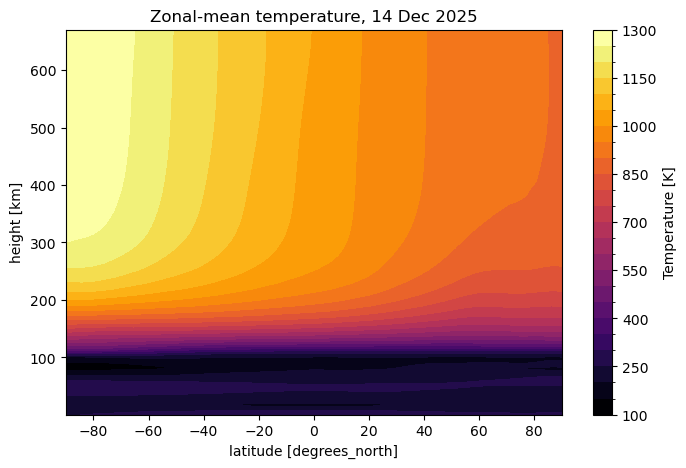

In [11]:
T_zonal = T.isel(time=0).mean("lon")
U_zonal = U.isel(time=0).mean("lon")

T_zonal.plot.contourf(x="lat", y="height", levels=30, cmap="inferno", figsize=(8, 5))
plt.title("Zonal-mean temperature, 14 Dec 2025")
plt.show()

The thermosphere (above ~120 km) reaches 800–1300 K through absorption of solar EUV, and
dominates the colour scale. Restricting the height range and setting the contour levels
explicitly reveals the structure below:

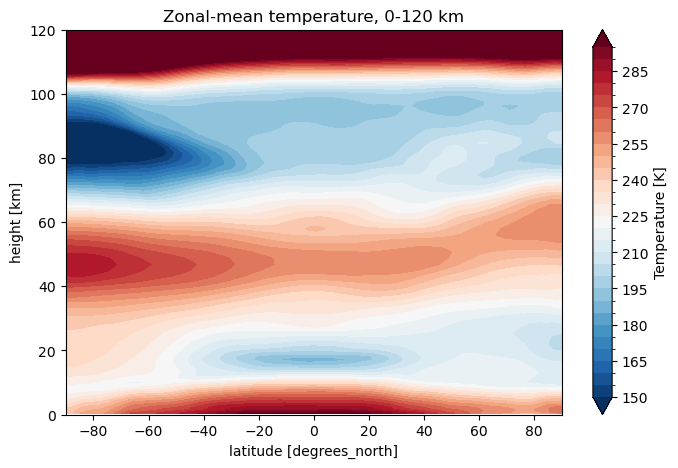

In [12]:
T_zonal.plot.contourf(x="lat", y="height", levels=np.arange(150, 300, 5), cmap="RdBu_r", ylim=(0, 120), figsize=(8, 5))
plt.title("Zonal-mean temperature, 0-120 km")
plt.show()

Features to identify: the tropopause (~10–17 km), the warm stratopause near 50 km (ozone
heating), and the mesopause at 80–100 km, which is coldest over the **summer** (southern)
pole. That summer-pole minimum is far from radiative equilibrium; it is maintained by
gravity-wave-driven upwelling and adiabatic cooling.

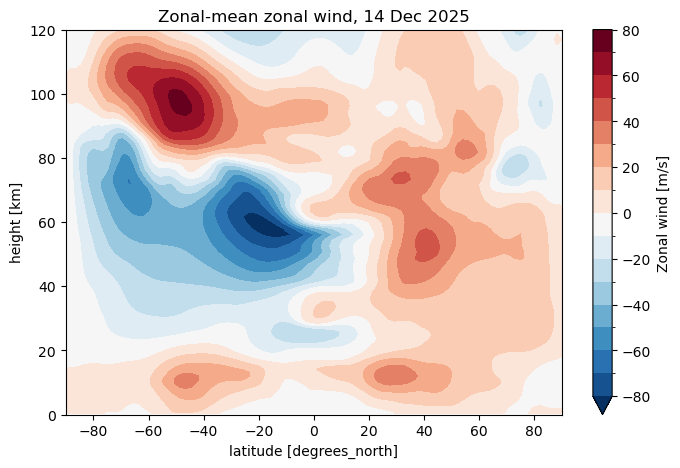

In [13]:
U_zonal.plot.contourf(x="lat", y="height", levels=np.arange(-80, 90, 10), cmap="RdBu_r", ylim=(0, 120), figsize=(8, 5))
plt.title("Zonal-mean zonal wind, 14 Dec 2025")
plt.show()

**Exercise.** Repeat the zonal-mean plots for the second day (`isel(time=1)`), and plot the
difference between the two days.

## 4. Maps

Selecting a single level (and time) leaves a `(lat, lon)` field, which `.plot()` draws as a map.
`method="nearest"` picks the level closest to 1 hPa (about 48 km).

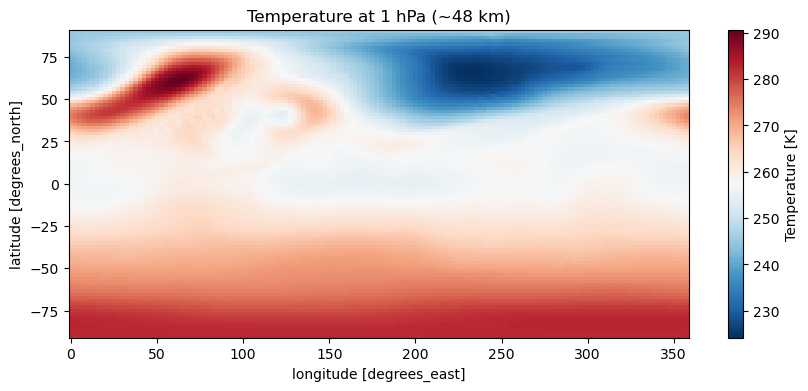

In [14]:
T_1hPa = T.isel(time=0).sel(lev=1, method="nearest")

T_1hPa.plot(cmap="RdBu_r", figsize=(10, 4))
plt.title("Temperature at 1 hPa (~48 km)")
plt.show()

To select by height instead, find the index of the level whose height is closest to the
target: `abs(height_km - 250).argmin()`.

level index 28 at 252 km


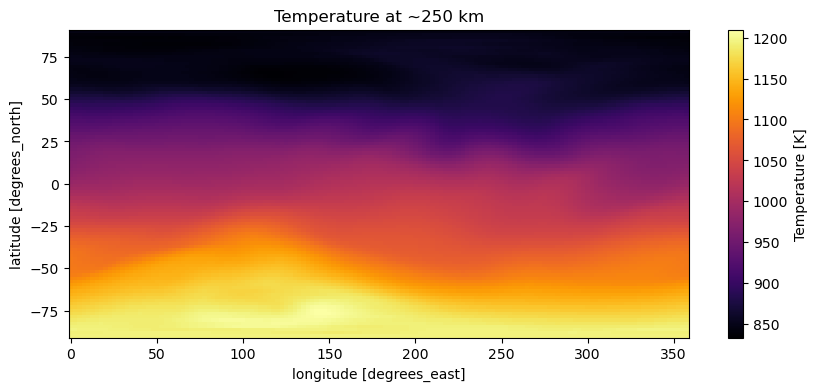

In [15]:
i_250 = int(abs(height_km - 250).argmin())
print(f"level index {i_250} at {float(height_km[i_250]):.0f} km")

T_250km = T.isel(time=0, lev=i_250)

T_250km.plot(cmap="inferno", figsize=(10, 4))
plt.title("Temperature at ~250 km")
plt.show()

### Total electron content

`ElecColDens` is the vertically integrated electron density, the **total electron content**
(TEC), in TEC units (1 TECU = 10¹⁶ electrons m⁻²). TEC sets the ionospheric delay of GNSS
signals. It has no `lev` dimension.

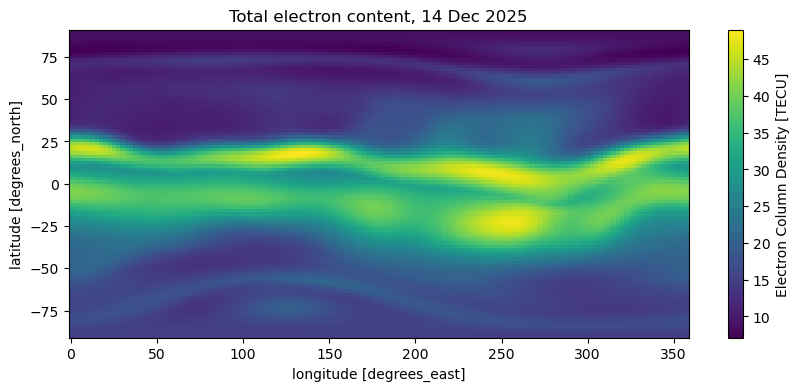

In [16]:
tec = daily["ElecColDens"]

tec.isel(time=0).plot(cmap="viridis", figsize=(10, 4))
plt.title("Total electron content, 14 Dec 2025")
plt.show()

The two crests either side of the magnetic equator are the **equatorial ionisation anomaly**,
formed by the equatorial fountain effect (E × B uplift followed by diffusion along field lines).

### What `.plot()` does for 2D data

For 2D data, `.plot()` calls `plt.pcolormesh(x, y, values)`. The same map drawn directly with
matplotlib:

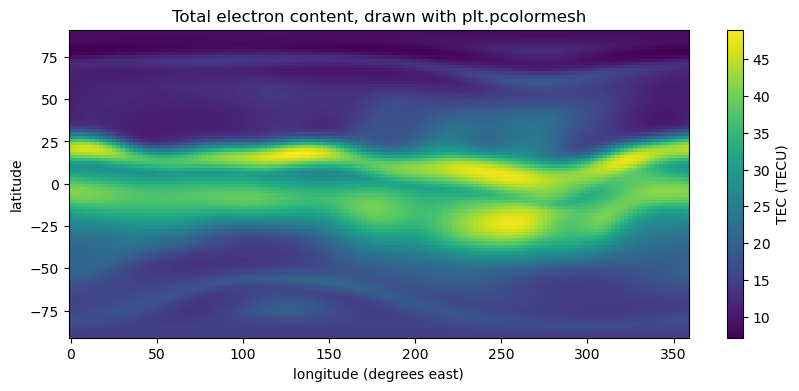

In [17]:
tec_day1 = tec.isel(time=0)

plt.figure(figsize=(10, 4))
plt.pcolormesh(tec_day1["lon"], tec_day1["lat"], tec_day1, cmap="viridis")
plt.colorbar(label="TEC (TECU)")
plt.xlabel("longitude (degrees east)")
plt.ylabel("latitude")
plt.title("Total electron content, drawn with plt.pcolormesh")
plt.show()

`.plot()` is quicker for exploration; using matplotlib directly gives full control for
publication figures. The two can be mixed: after `.plot()` the usual `plt.title`, `plt.ylim`,
etc. still apply.

**Exercise.** Plot a map of the zonal wind `U` at 1 hPa. Identify the polar vortex.

## 5. Time–height sections from station output

The station files are opened the same way. Each file holds one day of 5-minute output.

In [18]:
station = xr.open_mfdataset(f"{DATA_DIR}/h3_20e_70n_13e_55n/{CASE}.cam.h3.*.nc")

print(station.sizes["time"], "times from", station["time"].values[0], "to", station["time"].values[-1])
print([name for name in station.data_vars if name.startswith("T")])

576 times from 2025-12-15T00:05:00.000000000 to 2025-12-17T00:00:00.000000000
['TElec_13e_55n', 'TElec_20e_70n', 'TIon_13e_55n', 'TIon_20e_70n', 'TTGW_13e_55n', 'TTGW_20e_70n', 'T_13e_55n', 'T_20e_70n']


CAM writes each station as separate variables with a location suffix: `T_20e_70n` is
temperature at Tromsø. Each carries length-1 latitude and longitude dimensions;
`.squeeze()` removes them, leaving `(time, lev)`.

In [19]:
height_tromso_km = (station["Z3GM_20e_70n"].squeeze().mean("time") / 1000).compute()
height_tromso_km.attrs["long_name"] = "height"
height_tromso_km.attrs["units"] = "km"

height_copenhagen_km = (station["Z3GM_13e_55n"].squeeze().mean("time") / 1000).compute()
height_copenhagen_km.attrs["long_name"] = "height"
height_copenhagen_km.attrs["units"] = "km"

T_tromso = station["T_20e_70n"].squeeze().assign_coords(height=height_tromso_km)
T_copenhagen = station["T_13e_55n"].squeeze().assign_coords(height=height_copenhagen_km)

T_tromso

<xarray.DataArray 'T_20e_70n' (time: 576, lev: 145)> Size: 334kB
dask.array<getitem, shape=(576, 145), dtype=float32, chunksize=(288, 145), chunktype=numpy.ndarray>
Coordinates:
    lat_physgrid_70n    float64 8B 69.16
  * lev                 (lev) float64 1kB 4.055e-10 5.207e-10 ... 977.5 992.5
    lon_physgrid_20e    float64 8B 20.0
  * time                (time) datetime64[ns] 5kB 2025-12-15T00:05:00 ... 202...
    lat_fv_centers_70n  float64 8B 69.16
    lon_fv_centers_20e  float64 8B 20.0
    height              (lev) float32 580B 603.3 589.1 575.1 ... 0.7229 0.6022
Attributes:
    mdims:      1
    units:      K
    long_name:  Temperature
    basename:   T

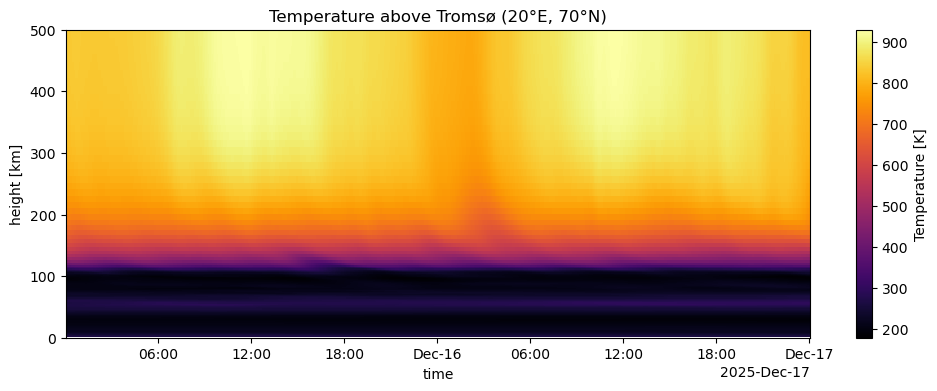

In [20]:
T_tromso.plot(x="time", y="height", cmap="inferno", ylim=(0, 500), figsize=(12, 4))
plt.title("Temperature above Tromsø (20°E, 70°N)")
plt.show()

Electron density spans several orders of magnitude, so plot its base-10 logarithm:

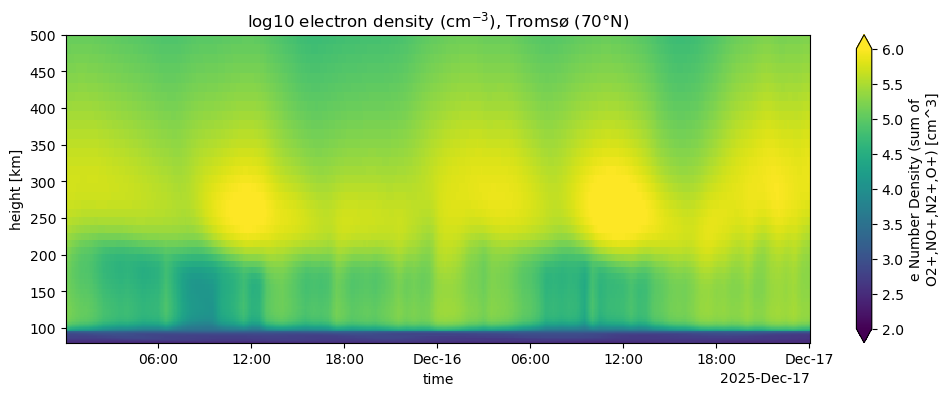

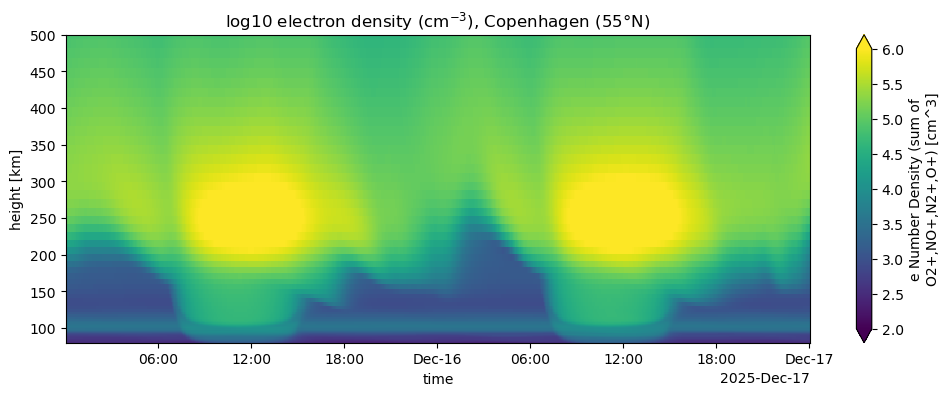

In [21]:
Ne_tromso = station["EDens_20e_70n"].squeeze().assign_coords(height=height_tromso_km)
Ne_copenhagen = station["EDens_13e_55n"].squeeze().assign_coords(height=height_copenhagen_km)

np.log10(Ne_tromso).plot(x="time", y="height", vmin=2, vmax=6, ylim=(80, 500), figsize=(12, 4))
plt.title("log10 electron density (cm$^{-3}$), Tromsø (70°N)")
plt.show()

np.log10(Ne_copenhagen).plot(x="time", y="height", vmin=2, vmax=6, ylim=(80, 500), figsize=(12, 4))
plt.title("log10 electron density (cm$^{-3}$), Copenhagen (55°N)")
plt.show()

Over Copenhagen photoionisation produces a daytime ionosphere extending down to the E region
(~100 km), which decays after sunset. At Tromsø in December the Sun stays below the horizon at
ground level (polar night), so the daytime E and lower F region never form. At ~300 km the
horizon is depressed far enough that the upper atmosphere is still sunlit around noon, and a
weaker daytime F-region peak remains.

**Exercise.** Make a time–height plot of the zonal wind `U_20e_70n` between 0 and 150 km.
Look for downward phase progression, the signature of upward-propagating tides and
gravity waves.

## 6. Time series at a point

Selecting one station and one level leaves a 1D time series. Here, the level nearest 250 km:

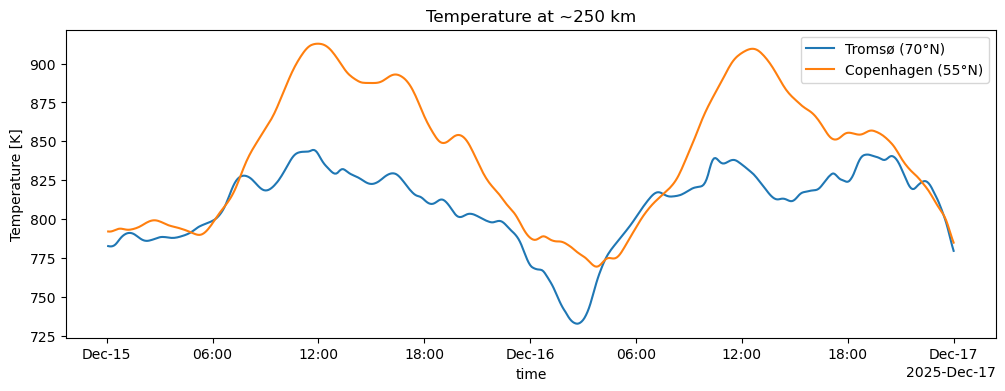

In [22]:
i_250 = int(abs(height_tromso_km - 250).argmin())

plt.figure(figsize=(12, 4))
T_tromso.isel(lev=i_250).plot(label="Tromsø (70°N)")
T_copenhagen.isel(lev=i_250).plot(label="Copenhagen (55°N)")
plt.legend()
plt.title("Temperature at ~250 km")
plt.show()

The files also contain the **solar zenith angle** (`SZA`, > 90° means the Sun is below the
horizon) and the geomagnetic **Kp index** used to drive high-latitude forcing.

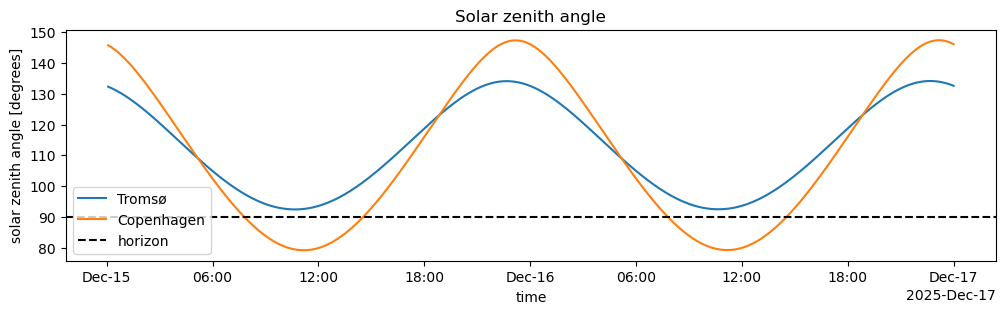

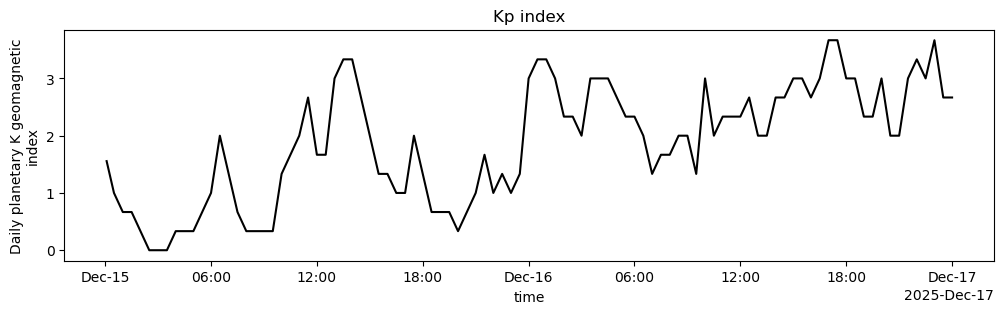

In [23]:
plt.figure(figsize=(12, 3))
station["SZA_20e_70n"].squeeze().plot(label="Tromsø")
station["SZA_13e_55n"].squeeze().plot(label="Copenhagen")
plt.axhline(90, color="black", linestyle="--", label="horizon")
plt.legend()
plt.title("Solar zenith angle")
plt.show()

plt.figure(figsize=(12, 3))
station["kp"].plot(color="black")
plt.title("Kp index")
plt.show()

At Tromsø the SZA never falls below 90°, which accounts for the smaller diurnal temperature
range there compared with Copenhagen.

**Exercise.** Plot the Tromsø temperature at ~100 km. How does the diurnal variation compare
with 250 km?

## 7. Time averages and area averages

### Time average

Reducing over `time` gives the mean profile over both days of station output (576 profiles):

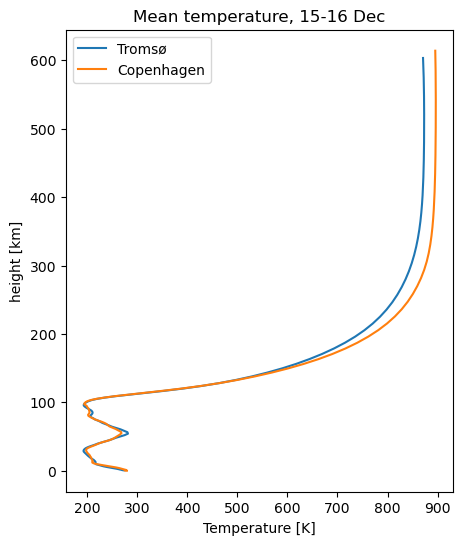

In [24]:
plt.figure(figsize=(5, 6))
T_tromso.mean("time").plot(y="height", label="Tromsø")
T_copenhagen.mean("time").plot(y="height", label="Copenhagen")
plt.legend()
plt.title("Mean temperature, 15-16 Dec")
plt.show()

and the same for the daily-mean TEC maps:

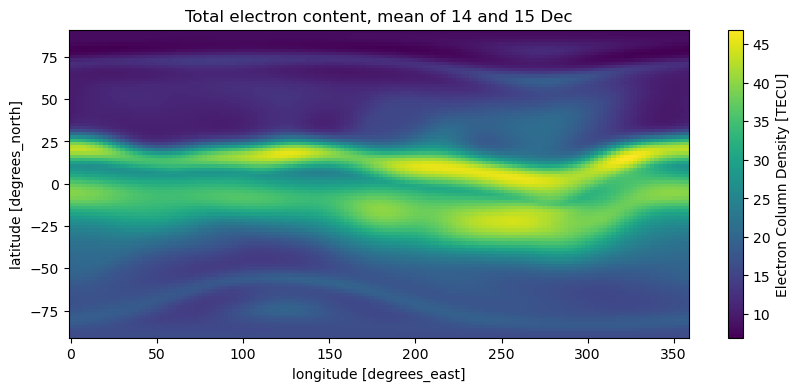

In [25]:
tec_mean = tec.mean("time")

tec_mean.plot(cmap="viridis", figsize=(10, 4))
plt.title("Total electron content, mean of 14 and 15 Dec")
plt.show()

### Area average over a region

Cut out a box with `.sel` and `slice(start, stop)`, then reduce over both horizontal dimensions:

In [26]:
scandinavia = tec_mean.sel(lat=slice(55, 72), lon=slice(5, 30))

print(scandinavia.sizes)
print(f"mean TEC over Scandinavia: {float(scandinavia.mean()):.2f} TECU")

Frozen({'lat': 9, 'lon': 11})
mean TEC over Scandinavia: 10.55 TECU


### Area weighting

On a regular latitude–longitude grid the area of a cell is proportional to cos(latitude), so
an unweighted mean over-represents high latitudes. `.weighted(weights).mean(...)` computes
the weighted mean:

In [27]:
weights = np.cos(np.deg2rad(tec["lat"]))

print(f"unweighted global mean: {float(tec_mean.mean()):.2f} TECU")
print(f"area-weighted global mean: {float(tec_mean.weighted(weights).mean(['lat', 'lon'])):.2f} TECU")

unweighted global mean: 20.89 TECU
area-weighted global mean: 24.52 TECU


### Area average as a function of time and height

Without the time reduction, the result is one area mean per time step. Applied to the
3D temperature over the polar cap, this gives a mean profile for each day:

global-mean TEC per day: [25.27352465 23.76920169]


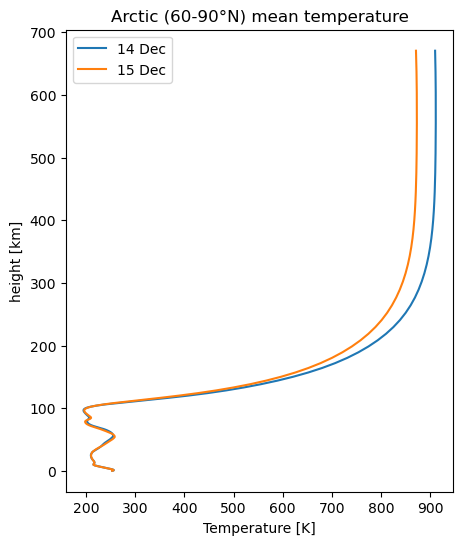

In [28]:
print("global-mean TEC per day:", tec.weighted(weights).mean(["lat", "lon"]).values)

polar_cap = T.sel(lat=slice(60, 90))
polar_cap_profile = polar_cap.weighted(np.cos(np.deg2rad(polar_cap["lat"]))).mean(["lat", "lon"])

plt.figure(figsize=(5, 6))
polar_cap_profile.isel(time=0).plot(y="height", label="14 Dec")
polar_cap_profile.isel(time=1).plot(y="height", label="15 Dec")
plt.legend()
plt.title("Arctic (60-90°N) mean temperature")
plt.show()

**Exercises.**
1. Compute the area-mean TEC over the UK (50–60°N, 8°W–2°E). The box crosses the 0°/360°
   longitude seam, so either combine two slices or convert longitudes to −180–180 with
   `tec.assign_coords(lon=((tec.lon + 180) % 360) - 180).sortby("lon")`.
2. Repeat the polar-cap profile for the Antarctic (90–60°S) and compare the summer and winter
   mesopause temperatures.

## Summary

| task | xarray |
|---|---|
| open one file | `xr.open_dataset(path)` |
| open many files | `xr.open_mfdataset("dir/*.cam.h2.*.nc")` |
| select a variable | `ds["T"]` |
| select by value | `.sel(lat=70, method="nearest")`, `.sel(lat=slice(55, 72))` |
| select by position | `.isel(time=0)` |
| reduce along dimensions | `.mean("lon")`, `.mean("time")`, `.mean(["lat", "lon"])` |
| area-weighted mean | `.weighted(np.cos(np.deg2rad(lat))).mean(["lat", "lon"])` |
| drop length-1 dimensions | `.squeeze()` |
| add a coordinate | `.assign_coords(height=height_km)` |
| evaluate a lazy (dask) result | `.compute()` |
| line plot (1D) / colour mesh (2D) | `da.plot()` |
| choose axes | `da.plot(x="time", y="height")` |
| filled contours | `da.plot.contourf(x="lat", y="height", levels=...)` |
| matplotlib equivalents | `plt.plot(x, y)`, `plt.pcolormesh(x, y, values)` |